# Preprocessing in practice

Missing values, normalization and train/validation/test splits.

We use the **Wine** dataset that comes with scikit-learn: 178 wines, 13 chemical measurements per wine, and 3 grape varieties as labels. No download is needed.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.neighbors import KNeighborsClassifier

plt.rcParams["figure.figsize"] = (8, 4)

## 1. Look at the data

In [2]:
wine = load_wine(as_frame=True)
df = wine.frame              # features + a 'target' column
X = wine.data.to_numpy()     # feature matrix, shape (n, d)
y = wine.target.to_numpy()   # labels, shape (n,)

print("X:", X.shape, "  y:", y.shape)
print("classes:", wine.target_names.tolist())
df.head()

X: (178, 13)   y: (178,)
classes: ['class_0', 'class_1', 'class_2']


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


The features live on very different scales. Compare the min and max columns, for example `hue` against `proline`.

In [3]:
df.describe().loc[["min", "max", "mean", "std"]].T.round(2)

,min,max,mean,std
alcohol,11.03,14.83,13.00,0.81
malic_acid,0.74,5.80,2.34,1.12
ash,1.36,3.23,2.37,0.27
alcalinity_of_ash,10.60,30.00,19.49,3.34
magnesium,70.00,162.00,99.74,14.28
total_phenols,0.98,3.88,2.30,0.63
flavanoids,0.34,5.08,2.03,1.00
nonflavanoid_phenols,0.13,0.66,0.36,0.12
proanthocyanins,0.41,3.58,1.59,0.57
color_intensity,1.28,13.00,5.06,2.32


## 2. Missing values

The wine data is complete, so we remove about 8% of the values at random to practise. Real data is rarely this tidy.

In [4]:
rng = np.random.default_rng(0)

X_gaps = X.copy()
mask = rng.random(X.shape) < 0.08     # about 8% of all cells
X_gaps[mask] = np.nan

df_gaps = pd.DataFrame(X_gaps, columns=wine.feature_names)
df_gaps.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,NaN,NaN,127.0,2.80,3.06,0.28,2.29,5.64,1.04,NaN,1065.0
1,NaN,1.78,2.14,11.2,100.0,2.65,2.76,NaN,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,NaN,2.87,21.0,118.0,2.80,2.69,NaN,1.82,4.32,1.04,2.93,735.0


### Find the gaps

total gaps: 192
rows with at least one gap: 114 of 178


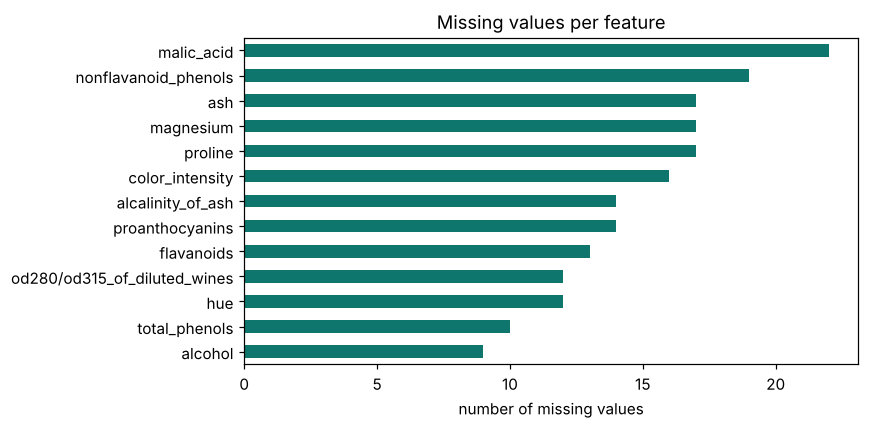

In [5]:
print("total gaps:", np.isnan(X_gaps).sum())
print("rows with at least one gap:", np.isnan(X_gaps).any(axis=1).sum(), "of", len(X_gaps))

df_gaps.isna().sum().sort_values().plot.barh(color="#0F766E")
plt.xlabel("number of missing values")
plt.title("Missing values per feature")
plt.tight_layout()
plt.show()

### Watch out for hidden codes

Sometimes "missing" is written as a number. Check the min and max of every column.

In [6]:
ages = pd.Series([25, 41, -999, 58, 0, 64], name="age")
print(ages.describe()[["min", "max"]])       # -999 gives it away

ages_clean = ages.replace([-999, 0], np.nan)
print(ages_clean.tolist())

min   -999.0
max     64.0
Name: age, dtype: float64
[25.0, 41.0, nan, 58.0, nan, 64.0]


### Strategy 1: drop rows with gaps

In [7]:
rows_ok = ~np.isnan(X_gaps).any(axis=1)
print("rows kept:", rows_ok.sum(), "of", len(X_gaps))

rows kept: 64 of 178


With many features, even a few gaps per column remove most of the rows. Dropping rows is rarely a good option here.

### Strategy 2: fill with the median

In [8]:
medians = np.nanmedian(X_gaps, axis=0)                # one median per column
X_filled = np.where(np.isnan(X_gaps), medians, X_gaps)

print("gaps left:", np.isnan(X_filled).sum())
pd.DataFrame(X_filled, columns=wine.feature_names).head()

gaps left: 0


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.35,19.5,127.0,2.80,3.06,0.28,2.29,5.64,1.04,2.80,1065.0
1,13.05,1.78,2.14,11.2,100.0,2.65,2.76,0.34,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,1.82,2.87,21.0,118.0,2.80,2.69,0.34,1.82,4.32,1.04,2.93,735.0


The same with scikit-learn:

In [9]:
from sklearn.impute import SimpleImputer

imp = SimpleImputer(strategy="median")
X_filled_sk = imp.fit_transform(X_gaps)

print("same result as NumPy:", np.allclose(X_filled, X_filled_sk))

same result as NumPy: True


### Strategy 3: fill, and remember where the gaps were

In [10]:
X_flagged = np.hstack([X_filled, np.isnan(X_gaps)])
print(X_flagged.shape)       # 13 features + 13 "was missing" columns

(178, 26)


> We filled using **all** rows here to keep the demo simple. In section 5 we do it properly: the medians are learned from the training set only.

## 3. Normalization

Two common scalers, written with NumPy broadcasting (`axis=0` means one value per feature).

In [11]:
def minmax(X):
    return (X - X.min(axis=0)) / (X.max(axis=0) - X.min(axis=0))

def zscore(X):
    return (X - X.mean(axis=0)) / X.std(axis=0)

X_mm = minmax(X)
X_z = zscore(X)

print("min-max: min", X_mm.min(), "  max", X_mm.max())
print("z-score: means", X_z.mean(axis=0)[:3].round(2) + 0.0, "...  stds", X_z.std(axis=0)[:3].round(2), "...")

min-max: min 0.0   max 1.0
z-score: means [0. 0. 0.] ...  stds [1. 1. 1.] ...


In [12]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

print("min-max matches scikit-learn:", np.allclose(X_mm, MinMaxScaler().fit_transform(X)))
print("z-score matches scikit-learn:", np.allclose(X_z, StandardScaler().fit_transform(X)))

min-max matches scikit-learn: True
z-score matches scikit-learn: True


### Why it matters: which features decide the distance?

k-NN and many other methods are built on distances. Take two wines and see how much each feature contributes to the squared distance between them.

In [13]:
def share_of_distance(a, b, names):
    d = (a - b) ** 2
    return pd.Series(d / d.sum(), index=names).sort_values(ascending=False).head(3).round(3)

print("Raw features:")
print(share_of_distance(X[0], X[1], wine.feature_names))
print()
print("Standardized features:")
print(share_of_distance(X_z[0], X_z[1], wine.feature_names))

Raw features:
magnesium            0.746
proline              0.230
alcalinity_of_ash    0.020
dtype: float64

Standardized features:
magnesium            0.294
proanthocyanins      0.256
alcalinity_of_ash    0.143
dtype: float64


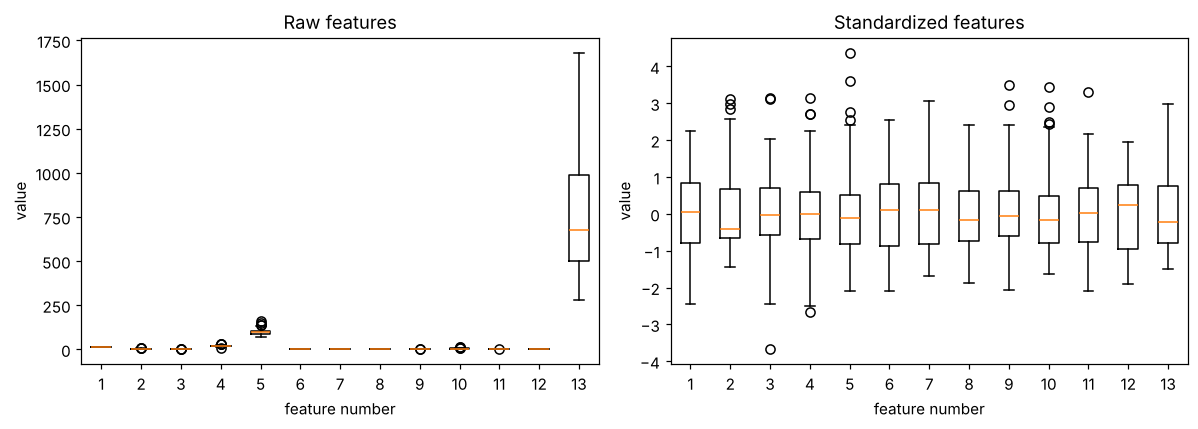

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].boxplot(X)
axes[0].set_title("Raw features")

axes[1].boxplot(X_z)
axes[1].set_title("Standardized features")

for ax in axes:
    ax.set_xlabel("feature number")
    ax.set_ylabel("value")
plt.tight_layout()
plt.show()

## 4. Train / validation / test split

First by hand with NumPy: shuffle the row numbers once, then slice them into three groups.

In [15]:
rng = np.random.default_rng(42)
idx = rng.permutation(len(X))              # shuffle the row numbers

n_train = int(0.70 * len(X))
n_val   = int(0.15 * len(X))

train = idx[:n_train]
val   = idx[n_train:n_train + n_val]
test  = idx[n_train + n_val:]

print("train:", len(train), "  val:", len(val), "  test:", len(test))

train: 124   val: 26   test: 28


A purely random split can skew the class proportions, especially in small sets. Compare the share of each wine variety:

In [16]:
def class_share(labels):
    return np.bincount(labels, minlength=3) / len(labels)

print("all:  ", class_share(y).round(2))
print("train:", class_share(y[train]).round(2))
print("val:  ", class_share(y[val]).round(2))
print("test: ", class_share(y[test]).round(2))

all:   [0.33 0.4  0.27]
train: [0.28 0.46 0.26]
val:   [0.35 0.31 0.35]
test:  [0.54 0.21 0.25]


With scikit-learn we can **stratify**: every split keeps the class proportions of the full data. `train_test_split` makes two sets per call, so we call it twice. From here on we use the data **with gaps**, as real data would be.

In [17]:
from sklearn.model_selection import train_test_split

# First split off the test set, then split the rest into train and validation
X_tmp, X_test, y_tmp, y_test = train_test_split(
    X_gaps, y, test_size=0.15, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(
    X_tmp, y_tmp, test_size=0.1765, stratify=y_tmp, random_state=42)

print("train:", X_train.shape, "  val:", X_val.shape, "  test:", X_test.shape)
print("train:", class_share(y_train).round(2))
print("val:  ", class_share(y_val).round(2))
print("test: ", class_share(y_test).round(2))

train: (124, 13)   val: (27, 13)   test: (27, 13)
train: [0.33 0.4  0.27]
val:   [0.33 0.41 0.26]
test:  [0.33 0.41 0.26]


## 5. Putting it together: learn from the training set only

Split first. Then learn the medians, means and standard deviations from the **training set** and apply them to all three sets.

In [18]:
# 1. Learn the medians from the TRAINING set only
medians = np.nanmedian(X_train, axis=0)

def fill(X):
    return np.where(np.isnan(X), medians, X)

X_train_f, X_val_f, X_test_f = fill(X_train), fill(X_val), fill(X_test)

# 2. Learn mean and standard deviation from the TRAINING set only
mu  = X_train_f.mean(axis=0)
std = X_train_f.std(axis=0)

def scale(X):
    return (X - mu) / std

X_train_s, X_val_s, X_test_s = scale(X_train_f), scale(X_val_f), scale(X_test_f)

print("train mean (first 3):", X_train_s.mean(axis=0)[:3].round(2) + 0.0)
print("val mean   (first 3):", X_val_s.mean(axis=0)[:3].round(2) + 0.0)

train mean (first 3): [0. 0. 0.]
val mean   (first 3): [-0.02 -0.17  0.11]


The validation means are close to 0 but not exactly 0. That is expected: the scale was learned from the training data only, just as it would be for new data in real use.

Does scaling help? Train k-NN and compare the accuracy on the **validation** set.

In [19]:
def knn_accuracy(X_tr, y_tr, X_ev, y_ev, k=5):
    model = KNeighborsClassifier(n_neighbors=k).fit(X_tr, y_tr)
    return model.score(X_ev, y_ev)

print("Filled, not scaled:", round(knn_accuracy(X_train_f, y_train, X_val_f, y_val), 3))
print("Filled and scaled: ", round(knn_accuracy(X_train_s, y_train, X_val_s, y_val), 3))

Filled, not scaled: 0.852
Filled and scaled:  0.926


Once the choices are made, the **test** set is used once, for the final number. It holds only 27 wines, so a single mistake moves the score by about 4 percentage points.

In [20]:
print("Final test accuracy:", round(knn_accuracy(X_train_s, y_train, X_test_s, y_test), 3))

Final test accuracy: 1.0


## 6. What leakage looks like

Compare two ways of scaling on the complete data, repeated over 100 random splits so that one lucky split does not decide the result:

- **leaky**: mean and standard deviation computed from *all* rows, test rows included
- **correct**: computed from the training rows only

In [21]:
def run_once(seed, leak):
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.3, stratify=y, random_state=seed)
    if leak:
        mu, std = X.mean(axis=0), X.std(axis=0)           # WRONG: includes test rows
    else:
        mu, std = X_tr.mean(axis=0), X_tr.std(axis=0)     # RIGHT: training rows only
    return knn_accuracy((X_tr - mu) / std, y_tr, (X_te - mu) / std, y_te)

leaky   = [run_once(seed, leak=True)  for seed in range(100)]
correct = [run_once(seed, leak=False) for seed in range(100)]

print(f"leaky:   {np.mean(leaky):.4f}")
print(f"correct: {np.mean(correct):.4f}")
print("splits where the two differ:", sum(a != b for a, b in zip(leaky, correct)), "of 100")

leaky:   0.9620
correct: 0.9624
splits where the two differ: 28 of 100


**Reading the result.** There is practically no difference here. A simple scaler on a small, clean dataset leaks very little, and the tiny gaps between the two numbers are noise (the order can even flip). That is what makes leakage dangerous: it is invisible. The habit costs nothing, and other steps can leak far more, for example choosing features or encoding categories with the help of all the labels before the split.

## 7. The tidy way: a pipeline

A scikit-learn `Pipeline` applies the right order automatically: every step learns from the training data only, and the validation and test data are only transformed.

In [22]:
from sklearn.pipeline import make_pipeline

pipe = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5),
)
pipe.fit(X_train, y_train)      # imputer and scaler learn from training data only

print("validation accuracy:", round(pipe.score(X_val, y_val), 3))

validation accuracy: 0.926


It matches the manual version from section 5.

## Summary

| Step | Remember |
|---|---|
| Missing values | Find the gaps and hidden codes first, then drop or fill on purpose. |
| Normalization | Scale features for distance-based and gradient-based models. |
| Splitting | Shuffle, stratify, and keep the test set for one final check. |
| Leakage | Anything learned from data (medians, means, scales) is learned from the training set only. |